# **Applied Data Analysis - Project Milestone P2**
## *How to be funny, for dummies.*

**<font size="4">Team: *JSON Derulo*</font>**<br>
- Adrián Fernández Lojo - adrian.fernandezlojo@epfl.ch
- Hanna Zwygart - hanna.zwygart@epfl.ch
- Jeremy Alexandre Serillon - jeremy.serillon@epfl.ch
- Mariem Maazoun - mariem.maazoun@epfl.ch
- Marina-Carmen Meredith Romero - marina.meredith@epfl.ch

Github repository: https://github.com/epfl-ada/ada-2025-project-json-derulo
<br><br><br>
_Note: Generative AI was used in this project to help us code some functions._
<br><br><br>

<!-- 
Make sure to read the [P2_README.md](P2_README.md) file.
<br><br>

**<font size="4">Table of Content</font>**

0. [Introduction](#0.-Introduction) <br>
0.1. [Abstract](#01-abstract) <br>
0.2. [Problematic](#02-problematic) <br>
0.3. [Dataset Description](#03-dataset-description) <br>
1. [General Data Visualizations](#1-general-data-visualizations) <br>
1.1. [Global Overview](#11-global-overview) <br>
1.2. [Overview of Contest Data](#12-overview-of-contest-data) <br>
1.3. [Intra Contest Overview](#13-intra-contest-overview) <br>
2. [Data pre-processing & cleaning](#2-data-pre-processing--cleaning) <br>
2.1. [Data Wrangling (filter, transform, ...)](#21-data-wrangling-filter-transform-) <br>
2.2. [Dataset Augmentation (enrich and adding new data)](#22-dataset-augmentation-enrich-and-adding-new-data) <br>
3. [Theme Analysis](#3-theme-analysis)
4. [Structural Analysis](#4-structural-analysis)
5. [Semantic Analysis](#5-semantic-analysis)
6. [Context Analysis](#6-context-analysis)
7. [Conclusion](#7-conclusion) -->

## 0. Introduction



### 0.1. Abstract

_"A day without laughter is a day wasted"_ - Charlie Chaplin

Each week, the NewYorker magazine provides an original cartoon, with a missing caption. Readers are thus invited to not only caption that week's contest, but also rate the previous week's image. 

In recent years, meme culture, and internet culture overall, has consistently prioritized shorter, and trending jokes. Tweets, TikToks, and even indirectly related formats, are tending to become shorter and have visual support. This is one of the many factors that could define how an image supported joke lands.

In this project, we have decided to dive into the NewYorker's caption contest dataset, which will give us great insights into humour, one of the most complex forms of human communication. We aim to discover the themes, structures, semantics, context and other subtleties that make something "funny".

<!-- Being funny is generally defined as a deeply cultural, societal and even contextual skill. When looking at our dataset, naturally, the following questions emerged : How can funniness be quantified ? Is humor objective ? 
Humour is a good reflection of society. The NYT caricatures are iconic, and captures years of societal, political and even government changes. We were therefore naturally drawn towards this dataset. We thought it would be interesting to see the evolutions of these captions over multiple years, through COVID etc…
The story we would like to tell is the story of what defines a funny or unfunny joke.
How do people react to the semantics and structure of a joke?  In our opinion, we would expect certain themes or joke structure to work better than others.  -->

### 0.2. Problematic

**Main problematics** <br>
How can we qualify and quantify jokes in terms of themes, structures and semantics (type of joke)?  <!-- and context (image desc. + temporal) -->

**Research questions and directions**<br>
Based on the objectives presented in the abstract, we aim to tackle the following concrete questions : 

1. Theme analysis:<br>
   1.a) What themes have a tendency to be ranked better ?<br>
   1.b) How theme relationships work between image and their text prompt (one way, or two-way) ?

2. Structural analysis: <br>
   2.a) Keep it short and simple: Are shorter jokes actually funnier ?<br>
   2.b) Are jokes with specific punctuation and rythms more effective ?

3. Semantic analysis:<br>
   3.a) What type of jokes over or underperform ? More specifically, which of the following categories perform best : dark humor, irony, social commentary, wordplay or absurdity ?

4. Context analysis: [this reasearch question was dropped, see below why]<br>
   4.a) How do external factors influence Humor ? In particular, can we link trends found in the dataset to societal landmarks ? 
<!-- 
1. Theme analysis: <br>
1.a. What themes have a tendency to be ranked better? We have found a LLM method which could help answer this question.<br>
1.b. How theme relationships work between image and their text prompt (one way, or two-way)?<br>

2. Structural analysis:<br>
2.a. Keep it short and simple : Are shorter jokes funnier? Are they more eﬀective by their ‘simplicity’?<br>
2.b. Are jokes with specific punctuation, rythme, … are effective?<br>

3. Semantic analysis:<br>
3.a. What type of jokes over or underperform? Types of joke: dark humor, irony, social commentary, wordplay, absurdity … [Deceptive Humor Dataset (DHD)](https://arxiv.org/abs/2503.16031)

4. Context influence, how do external factors influence Humor? (enrich dataset)<br>
4.a. Actuality (polytical, environmental, …) [GDELT](http://data.gdeltproject.org/events/index.html)<br>
4.b. Who is the targeted public, location, age? [Paper1](https://www.pewresearch.org/politics/2012/09/27/section-4-demographics-and-political-views-of-news-audiences/#:~:text=Regular%20readers%20of%20the%20New,talk%20programs%2C%20have%20older%20audiences.), [Paper2](https://www.library.illinois.edu/infosci/is-publications/civilian-publications/the-new-yorker/)<br>
4.c. [Dropped] Does an image's complexity visually play a role?<br>

5. [Dropped] How well can NLP perform in these types of contexts ? -->


### 0.3. Dataset description

The NewYorker's caption contest dataset follows the structure depicted below:
```bash
.
├── contests.json
├── data/
│   ├── 510.csv
│   ├── 511.csv
│   ...
│   ├── 894.csv
│   └── 895.csv
└── images/
    ├── 510.jpg
    ├── 511.jpg
    ...
    ├── 894.jpg
    └── 895.jpg
```

The ```contest.json``` holds the following data: _image path_, corresponding .csv _data path_ & _metadata_. The _metadata_ is a dictionary containing: the number of captions (present in the corresponding .csv file), image locations description (e.g. "streets", "a field", "wedding", ...), images descriptions ("A man walks outside."), image uncanny descriptions, related questions & related Wikipedia entities.

The corresponding contest image csv files, e.g. ```510.csv```, hold the following keys: <br>
funniness rank 'rank', 'caption', 'mean', 'precision', 'votes', 'not_funny', 'somewhat_funny' & 'funny'.


#### Scoring methods:

Linkert scale method:

|      Rating    |  Score |
| :-------------:| :----: |
| not funny      |  +1    |
| somewhat_funny |  +2    |
| funny          |  +3    |

The mean is the Arithmetic mean of all the scores for a specific caption $\sum_{i=1}^{n} score_i / n$ where $n$ is the number of votes <br>

The precision is the Standard Error of the Mean (SEM) $\sigma / \sqrt{n}$ where $\sigma$ is the standard deviation of the scores $\sigma^2=\frac{1}{n}\sum_{i=1}^{n}(mean-score_i)^2$. <br>



The dataframes are already sorted by the mean so we wont change the order <br>


## 1. General Data Visualizations

In [2]:
# General
import os
from pathlib import Path

# data manipulation
import json
import pandas as pd
# import numpy as np

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt
# from matplotlib import cm

# Interactive Jupyter
from IPython.display import display

# others
import contractions
from scipy.stats import pearsonr, ttest_ind 
import nltk
nltk.download('stopwords')

# Custom utility python files
import utils.visualization as viz # custom visualization utils in '/utils/visualization.py'
import utils.visualization2 as viz2 # custom visualization utils in '/utils/visualization2.py'
import utils.data_wrangling as dw # custom data wrangling utils in '/utils/data_wrangling.py'
import utils.structural_analysis as ut # custom structural analysis utils in '/utils/structural_analysis.py'
# import utils.data_augmentation as da # custom data augmentation utils in '/utils/data_augmentations.py'

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/jeremyserillon/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [3]:
# PATH PROJECT SETUP
PROJECT_ROOT = Path.cwd().parent.parent
FIGURES_DIR = PROJECT_ROOT / 'figures'

# DATA DIRECTORIES
DATA_DIR = PROJECT_ROOT / 'data' / 'newyorker_caption_contest'
JSON_DIR = DATA_DIR / 'contests.json'
CSV_DIR = DATA_DIR / 'data'
CSV_CLEAN_DIR = DATA_DIR / 'data_cleaned'
IMG_DIR = DATA_DIR / 'images'

print("Project path setup:")
print("PROJECT_ROOT:  ", PROJECT_ROOT)
print("FIGURES_DIR:   ", FIGURES_DIR)
print("\nDATA_DIR:      ", DATA_DIR)
print("JSON_DIR:      ", JSON_DIR)
print("CSV_DIR:       ", CSV_DIR)
print("CSV_CLEAN_DIR: ", CSV_CLEAN_DIR)
print("IMG_DIR:       ", IMG_DIR)

Project path setup:
PROJECT_ROOT:   /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo
FIGURES_DIR:    /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/figures

DATA_DIR:       /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest
JSON_DIR:       /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest/contests.json
CSV_DIR:        /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest/data
CSV_CLEAN_DIR:  /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest/data_cleaned
IMG_DIR:        /Users/jeremyserillon/Desktop/ada-2025-project-json-derulo/data/newyorker_caption_contest/images


### 1.1. Global Overview

Let us take a look at our raw dataset. Feel free to play with the slider to visualize different contest images and corresponding metadatas (if any).

In [4]:
# Load the JSON file => pandas DataFrame
file_path = str(JSON_DIR)
with open(file_path, "r") as file:
    contests = json.load(file)
contests_df = pd.DataFrame(contests)

# Visualize the contests with interactive viewer
viewer = viz.make_contest_viewer(contests_df, file_path)
display(viewer)

Once you have selected a contest ID with the slider, run the next cell to visualize some plots of the corresponding .CSV file.

Current selected 'contest_id' = 510


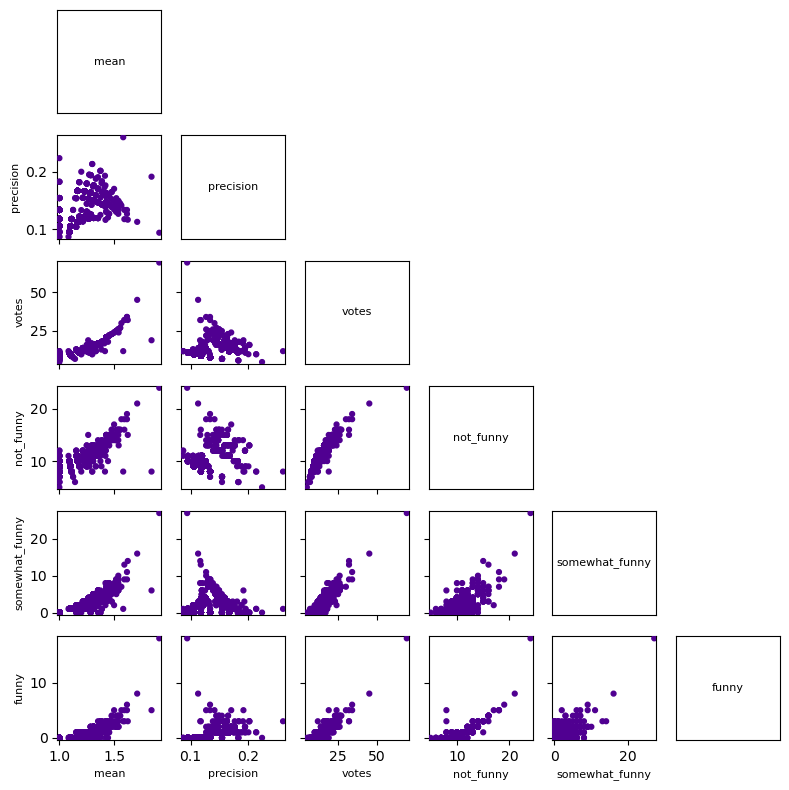

In [5]:
contest_id = int(viewer.slider.value)
print("Current selected 'contest_id' =", contest_id)

# Load corresponding CSV file
contest_row = contests_df[contests_df["contest_id"] == contest_id]
if not contest_row.empty:
    csv_rel_path = contest_row.iloc[0]["data"]
    csv_path = os.path.join(os.path.dirname(file_path), csv_rel_path)
    if os.path.exists(csv_path):
        df_current = pd.read_csv(csv_path)
        viz.plot_df_pairgrid(df_current, cols=["mean","precision","votes", "not_funny",
                                               "somewhat_funny", "funny"],
                             trace="none", figsize=(8,8),
                             include_upper=False, diagonal="name")
    else:
        print(f"CSV file not found at {csv_path}")
else:
    print(f"No contest found for contest_id {contest_id}")

In [6]:
print(contests_df.count())

contest_id    384
image         384
data          384
metadata      240
dtype: int64


votes distribution

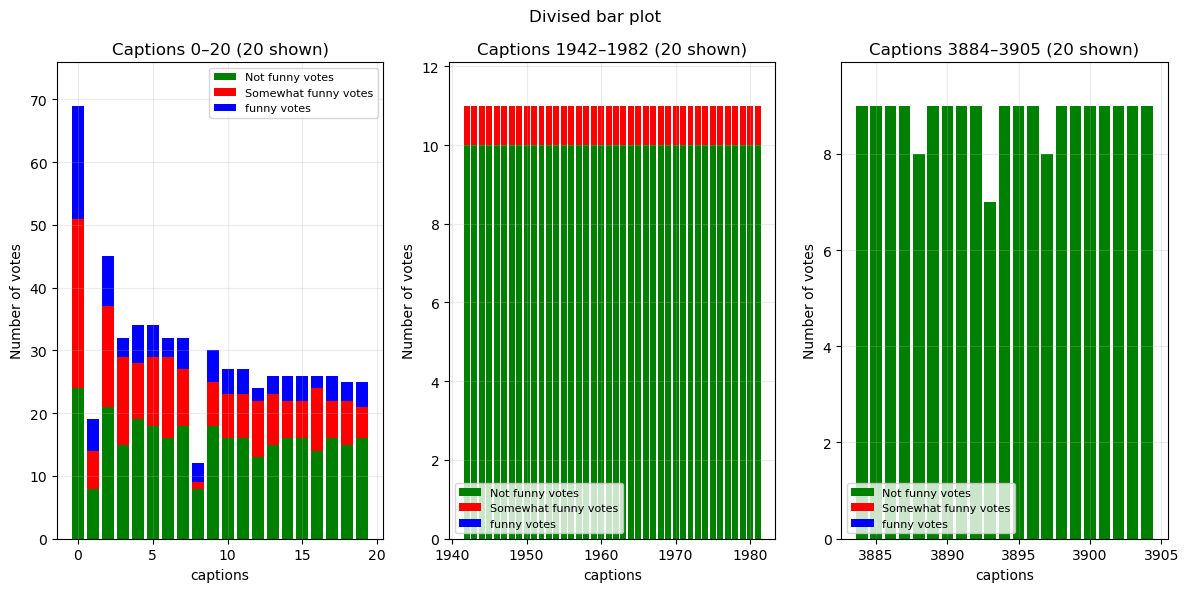

In [7]:
filename = f"{contest_id}.csv"
file_path = os.path.join(CSV_DIR, filename)
df=pd.read_csv(file_path)
viz2.plot_divised_histo_stacked(pd.read_csv(file_path))

means distribution :

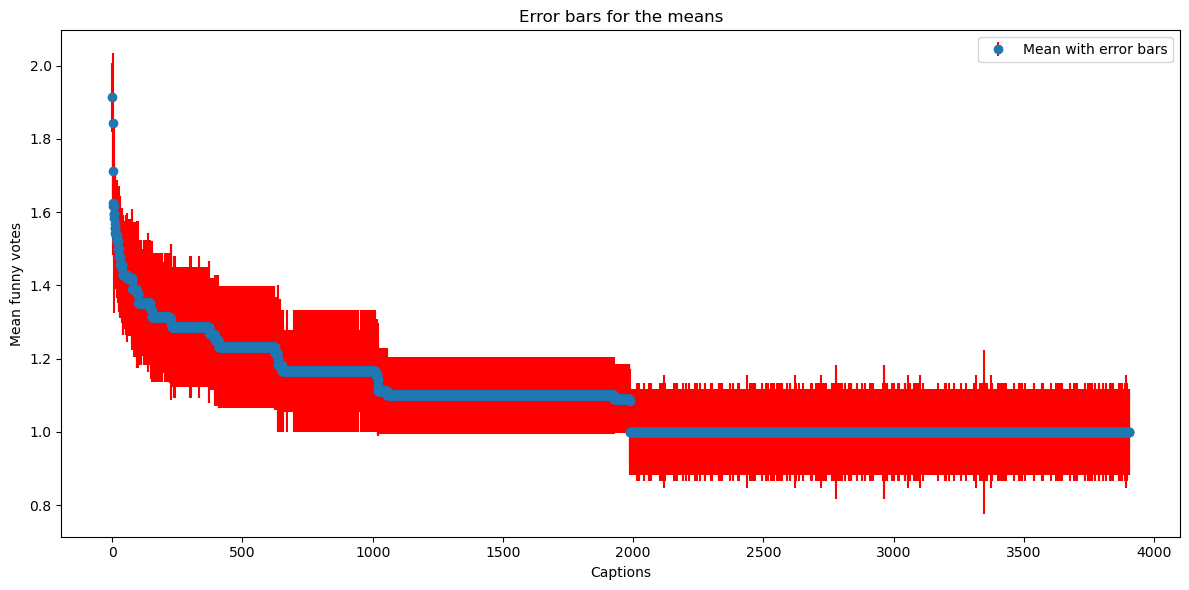

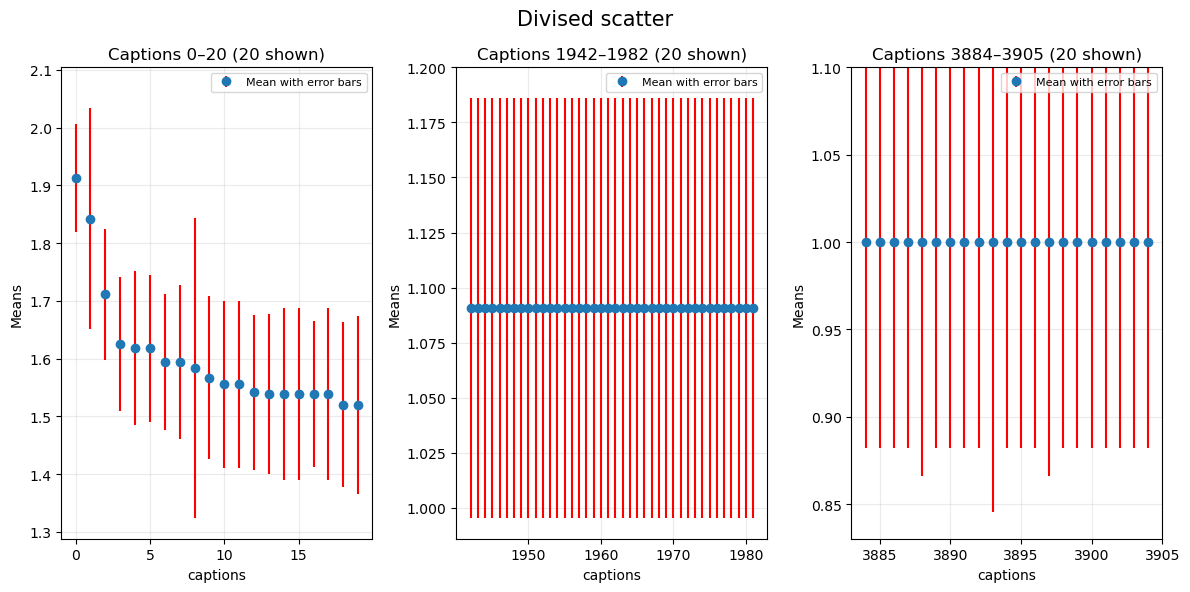

In [8]:
viz2.scatter_error(df)
viz2.plot_divised_scatter_error(df)

It looks like a heavy-tailed distribution!

Some data exploration : <br>
<br>
-Top1 Means vs all context

File not found: 525.csv
File not found: 540.csv

Top 5 contests by mean of top 1 captions:
     Contest  Top1_Mean
88       600   2.998918
178      690   2.671296
43       555   2.634196
153      665   2.518294
7        517   2.391304

Bottom 5 contests by mean of top 1 captions:
     Contest  Top1_Mean
128      640   1.633028
383      895   1.632287
132      644   1.600000
125      637   1.576744
131      643   1.552036

Highest mean contest: #600.0 with mean score 2.999
Lowest mean contest: #643.0 with mean score 1.552


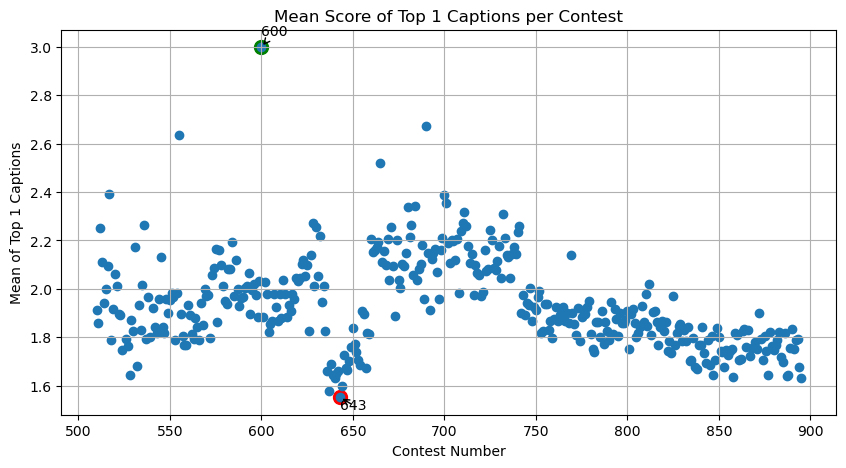

Contest with the best mean score on top 1 captions : 


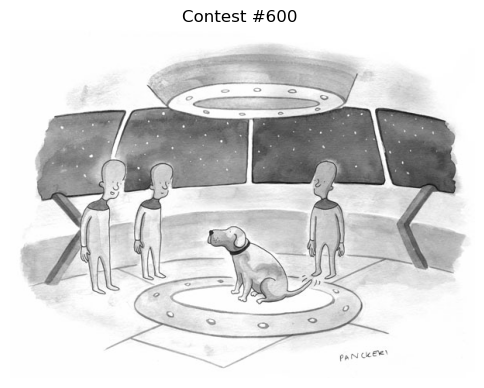


Contest 600 Top Caption:
Rank 1: 'Mission accomplished. We will report that this planet's inhabitants are friendly and playful.' with mean score 2.999
Contest with the worst mean score on top 1 captions : 


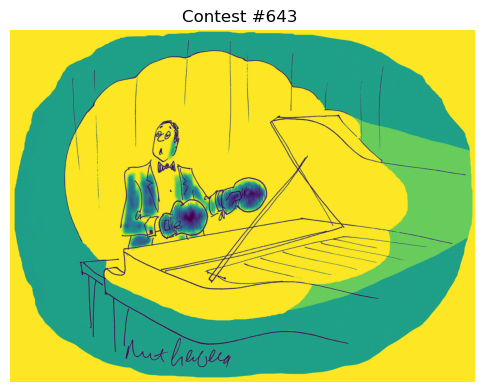


Contest 643 Top Caption:
Rank 1: 'My next selection sounds just like the last one.' with mean score 1.552


In [9]:
viz2.top1_means_vs_contests(CSV_DIR,IMG_DIR)

-Number of caption vs contests

File not found: 525.csv
File not found: 540.csv

Top 5 most popular contests:
     Contest  Num_Captions
204      716         15329
232      744         12354
228      740         11108
241      753         11069
195      707         10718

Top 5 least popular contests:
     Contest  Num_Captions
124      636          2930
86       598          2919
324      836          2032
322      834          1444
323      835          1066

Most popular contest: #716 with 15329 captions.
Least popular contest: #835 with 1066 captions.


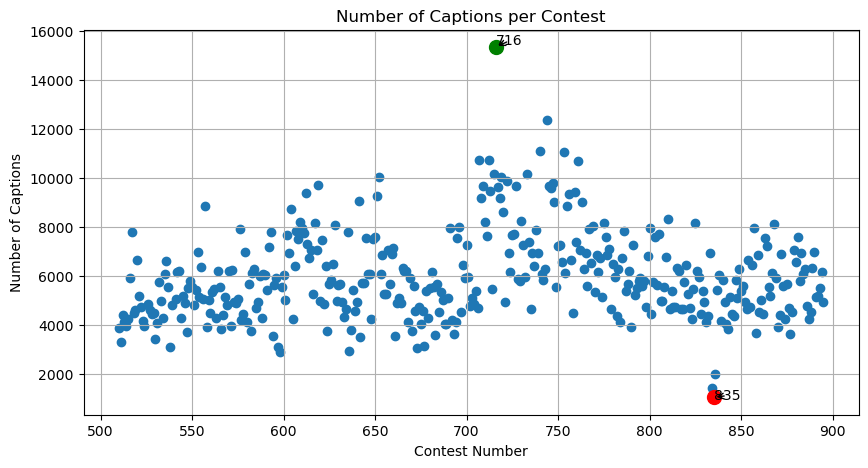

In [10]:
viz2.plot_number_of_captions_vs_contests(CSV_DIR,IMG_DIR)

it seems that contest 716 might be an outlier <br>
<br>

- Funy captions distribution

In [11]:
viz2.plot_funny_dist(CSV_DIR)

,contest_id,funny
229,510,519
250,511,460
228,512,476
207,513,545
273,514,2350
...,...,...
292,891,4355
269,892,4584
256,893,5031
222,894,5076


We should perhaps look more into contest 744. <br>

### 1.2. Overview of Contest Data (```contests.json``` file)

- missing metadatas (dictionaries): 144
- 2 missing contest: 525 & 540

In [12]:
# check missing contest (in the interval 510-895)
missing_contest = []
missing_csv = []
for id in range(510, 896):
    # missing contest id in json file
    if id not in contests_df['contest_id'].values:
        missing_contest.append(id)
    # missing csv file in DATA_DIR
    csv_path = CSV_DIR / f"{id}.csv"
    if not csv_path.exists():
        missing_csv.append(id)
        
print("Missing contest IDs in json file:", missing_contest)
print("Contests with missing CSV files in DATA_DIR:", missing_csv)

Missing contest IDs in json file: [525, 540]
Contests with missing CSV files in DATA_DIR: [525, 540]


In [13]:
# check missing metadata for each (present) contest id
missing_metadata = contests_df[contests_df['metadata'].isnull()]
print(f"Count of missing metadata: {len(missing_metadata)}")
print("Contest IDs with missing metadata:", missing_metadata['contest_id'].tolist())

Count of missing metadata: 144
Contest IDs with missing metadata: [527, 564, 588, 597, 605, 615, 644, 647, 656, 657, 670, 714, 764, 765, 766, 767, 768, 769, 770, 771, 772, 773, 774, 775, 776, 777, 778, 779, 780, 781, 782, 783, 784, 785, 786, 787, 788, 789, 790, 791, 792, 793, 794, 795, 796, 797, 798, 799, 800, 801, 802, 803, 804, 805, 806, 807, 808, 809, 810, 811, 812, 813, 814, 815, 816, 817, 818, 819, 820, 821, 822, 823, 824, 825, 826, 827, 828, 829, 830, 831, 832, 833, 834, 835, 836, 837, 838, 839, 840, 841, 842, 843, 844, 845, 846, 847, 848, 849, 850, 851, 852, 853, 854, 855, 856, 857, 858, 859, 860, 861, 862, 863, 864, 865, 866, 867, 868, 869, 870, 871, 872, 873, 874, 875, 876, 877, 878, 879, 880, 881, 882, 883, 884, 885, 886, 887, 888, 889, 890, 891, 892, 893, 894, 895]


### 1.3. Intra Contest Overview (.csv files)

- corrupted rows: in all ... we have 64'007 corrupted rows in all of the .csv files for a total of 2'292'677 rows. Here is an example below of corrupted rows in file ```523.csv```, row n°492 to n°506. As we can not make an assumption of which number is exploitable, we decided to exclude those lines. For more details, please refer to section [2.1 Data Wrangling](#21-data-wrangling-filter-transform-).  <br><br>
    <img src="../../figures/documentation/corrupted-csv.png" width="600"/>
<br><br>
- missing 'rank' columns in some .csv file such as ```663.csv```. Although the 'rank' column was missing, the order of the .csv was preserved so we added it.


## 2. Data pre-processing & cleaning

Let's explore more in depth the data and clean it

### 2.1. Data Wrangling (filter, transform, ...)

All of the data filtering functions are available in data_filtering.py.
The first thing we have looked into is fixing our header on all our files. 

The expected headers are the following : 
| Header |
|-----------|
|rank|
|caption|
|mean|
|precision|
|votes|
|not_funny|
|somewhat_funny|
|funny|



Indeed, we have noticed that, in our total 300+ contest files, they did not have matching headers. The "rank" header was often missing.

In order to fix that, we have started by first checking which contest did not have the excpected headers, then fixing them. Details on this can be consulted in the [data_filtering.py](../../src/Milestone_P2/utils/data_filtering.py).
| Function | Description |
|-----------|-----------|
| has_correct_headers| prints an error message when the CSV file does not have the right headers  |
| fix_missing_rank | adds a rank column based on decreasing mean values.|

Secondly, we started to look deeper into our individual lines. Namely, we have found that some lines in our CSV files were not formatted corresponding to our 8 header categories.

The objective was to delete those data lines, as they are not exploitable in order to yield reliable results. To do so, we have coded 3 functions which help us detect, and eventually aim at deleting the corrupted lines. These functions are the following : 

| Function | Description |
|-----------|--------------|
| check_corruption| Returns a list of reasons if the line is corrupted, based on our pre-defined criterias|
| check_csv_file_for_corruption| Returns a list of row indices that are corrupted in a given CSV file as well as some other metrics|
| clean_csv_using_corruption|  Cleans a CSV file by removing corrupted rows found by check_csv_file_for_corruption as well as saves the cleaned file in a 'data_cleaned' folder in the same parent directory.|

The aim was to create a new folder called *data_cleaned*, which contains all our CSV files in their final, filtered form. However, we still need to tweak the clean_csv_using_corruption() function, before having the desired results.  Once again, details on the above-mentioned functions can be found in the following file : [data_filtering.py](../../src/Milestone_P2/utils/data_filtering.py).

First of all, we want to do a sanity check on our data to check if there are no errors in our data. To do so, we wrote the ```check_votes ()``` function from the file [data_wrangling.py](../../src/Milestone_P2/utils/data_wrangling.py). that checks if the num_votes in the json file actually corresponds to the sum of the votes in the csv files. We also manually checked if the number of rows in the csv files also correspond to the num_captions in the json.

We also noticed 2 missing contests: ```525``` and ```540```. 
=> reasons: filter data captions that are sensitive or sensitive context.
To counter that, we wrote 

### 2.2. Dataset Augmentation (enrich and adding new data)

We noticed that contest Metadata is missing from the json file in 144 contests like in contest 527 or contest 564 like shown above in 1.2 part. To rectify that, we buit the ```update_metadata_from_csv``` function from the file [data_wrangling.py](../../src/Milestone_P2/utils/data_wrangling.py) that adds the missing num_captions and num_votes to the metadata dictionary

In [14]:
df_contest_updated= dw.update_metadata_from_csv(contests_df,CSV_DIR)


We can then do the sanity check of votes on the given and added num_votes. This function compute the number of votes from the .csv and compares that number from the one given in the ```contests.json```  metadata. That way we can control if everything is in order.

In [15]:
dw.check_votes(df_contest_updated, CSV_DIR)

Total contests checked: 384
Matching vote counts: 384
Mismatches or missing: 0


,contest_id,csv_found,csv_votes,json_votes,match
0,510,True,41185,41185,True
1,511,True,28205,28205,True
2,512,True,21574,21574,True
3,513,True,16894,16894,True
4,514,True,95790,95790,True
...,...,...,...,...,...
379,891,True,928856,928856,True
380,892,True,788251,788251,True
381,893,True,1085745,1085745,True
382,894,True,878676,878676,True


We also added the dates corresponding to all the contests following the date of the first contest 510 (22 Feb 2016). To rectify that, we buit the ```add_contest_dates()``` function from the file [data_wrangling.py](../../src/Milestone_P2/utils/data_wrangling.py)

In [16]:
df_contest_dates= dw.add_contest_dates(df_contest_updated)
df_contest_dates.head()


,contest_id,image,data,metadata
0,510,images/510.jpg,data/510.csv,"{'num_captions': 3905, 'num_votes': 41185, 'im..."
1,511,images/511.jpg,data/511.csv,"{'num_captions': 3325, 'num_votes': 28205, 'im..."
2,512,images/512.jpg,data/512.csv,"{'num_captions': 4399, 'num_votes': 21574, 'im..."
3,513,images/513.jpg,data/513.csv,"{'num_captions': 4141, 'num_votes': 16894, 'im..."
4,514,images/514.jpg,data/514.csv,"{'num_captions': 3951, 'num_votes': 95790, 'im..."


## 3. Theme Analysis

### 3.1. Proposed Pipeline

Here are the main tools and techniques that will be used in the theme extraction pipeline:
   - Pre-process to keep only meaningful words ("This is politic." => "politic")
   - Sentence Embeddings (BERT / Sentence-BERT / CLIP text encoder) - converts text => semantic vector representation.
   - Spherical k-means - clusters embeddings to form our themes.
   - c-TF-IDF (**c**lass-based **T**erm **F**requency-**I**nverse **D**ocument **F**requency) - extracts and labels the most representative words for each cluster/theme.
   - (previously tested) BERTopic - topics clustering approach that inspired the pipeline but is less scalable and less controllable for large datasets such as ours.

We will extract our themes from our decscriptions/captions like so:
   - images descriptions processed all at once to allow clustering them to each other independantly from the captions.
   - captions processed for each contest internally: extract the themes of all the caption for all specific contest once at a time.
   
This allows us to analyse and discuss behaviours inside each contest and also to parts the computation. To do more general analysis across ALL the captions, we will then do additional clustering to group back all the intermidiate, contest-wise, results.

To assess whether image and caption themes are statistically associated, we will construct a contingency table of their co-occurrences and apply chi-square test or pointwise mutual information (PMI/NPMI) to identify theme pairs that occur significantly more or less often.

### 3.2. Tested method - proof of concept

We have done a proof of concept test file that you can found here at: [BERTopic_test.py](/src/Milestone_P2/utils/BERTopic_test.py). To synthesise, we use some text samples to test BERTopic.

Here is the input:
```python
    texts = ["This is a political caption.",                            # Test captions
            "This is a funny caption.",                                 #  |
            "This is a caption about animals.",                         #  V
            "This is a caption about technology.",
            "This is a caption about sports.",
            "This is a caption about food.",
            "This is a caption about travel.",
            "This is a caption about health.",
            "This is a caption about education.",
            "This is a caption about environment.",             
            "When the right woman comes along, I'll know it.",          # Captions from the dataset
            "Anyone who steps on me is out!",                           #  |
            "Guess I should have jumped from a few floors higher.",     #  V
            "Does this suit make me look flat?",
            "I used to lie in the gutter, but then I quit drinking.",
            "If you can meditate here, you can meditate anywhere."]
```
<br><br>
And here the results obtained with BERTopic by running the [BERTopic_test.py](/src/Milestone_P2/utils/BERTopic_test.py) file:
```bash
    2025-10-25 02:10:57,242 - BERTopic - Embedding - Transforming documents to embeddings.
    Batches: 100%|████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.23it/s]
    2025-10-25 02:10:58,076 - BERTopic - Embedding - Completed ✓
    2025-10-25 02:10:58,076 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
    OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
    2025-10-25 02:11:00,470 - BERTopic - Dimensionality - Completed ✓
    2025-10-25 02:11:00,470 - BERTopic - Cluster - Start clusterixng the reduced embeddings
    2025-10-25 02:11:00,471 - BERTopic - Cluster - Completed ✓
    2025-10-25 02:11:00,472 - BERTopic - Representation - Fine-tuning topics using representation models.
    2025-10-25 02:11:01,007 - BERTopic - Representation - Completed ✓

       Topic                                    Name  Count
    0     -1  -1_caption_animals_education_political      5
    1      0            0_caption_health_food_sports      3
    2      1            1_caption_technology_this_is      2
```


We can see that we obtain 3 clusters of themes with the corresponding instances count. We keep in mind that the more caption/text samples we will input to BERTopic => the most reliable the topics clustering results will be. As explained above, we started by using BERTopic inspired the pipeline but is less scalable and less controllable for large datasets such as ours. This is why we will use and study the option explained above in the futur.

## 4. Structural Analysis

### 4.1 Data handling, cleaning up for the structural analysis

Creating a general Dataframe of all the csv files.

In [17]:
base_path = str(CSV_DIR)

df = ut.load_all_contest_data(base_path, start_id=510, end_id= 895)

Missing files for contest IDs: [525, 540]
Successfully loaded 384 files
Total rows: 2292678


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2292678 entries, 0 to 2292677
Data columns (total 9 columns):
 #   Column          Dtype  
---  ------          -----  
 0   rank            float64
 1   caption         object 
 2   mean            float64
 3   precision       float64
 4   votes           int64  
 5   not_funny       int64  
 6   somewhat_funny  int64  
 7   funny           int64  
 8   contest_id      int64  
dtypes: float64(3), int64(5), object(1)
memory usage: 157.4+ MB


Make the captions more fluid by: 
- erasing unnecessary punctuations 
- lowercase all the captions 
- handling contractions to normalise all the captions 
        -> necessary for comparison 

In [19]:
# check for missing values and fill NaN w/ empty string or remove them
print(f"missing values in caption: {df['caption'].isna().sum()}")
df["caption"] = df["caption"].fillna("")

# erase unnecessary punctuations :
df["caption"] = df["caption"].str.replace(r"[--]", " ", regex=True)
df["caption"] = df["caption"].str.replace(r"[.,?]", " ", regex=True)

# lowercase : 
df["caption"] = df["caption"].str.lower()

# contractions :
df["caption"] = df["caption"].apply(lambda x: contractions.fix(x))   

print(df["caption"].head()) # check

missing values in caption: 52
0           i am a congressman  obstruction is my job 
1    i am what they mean when they say  'the middle...
2                    does this suit make me look flat 
3    when the right woman comes along  i will know it 
4    i used to lie in the gutter  but then i quit d...
Name: caption, dtype: object


### 4.2 Are longer jokes funnier than shorter ones? What about jokes with more complex vocabulary?

How many words and characters are there in each caption ?

In [20]:
# words
df["word_counts"] = [len(line.split()) for line in df["caption"]]

# characters 
df["length"] = [len(line) for line in df["caption"]]

# average of words and characters
print(f"avg word count: {df['word_counts'].mean():.2f}")
print(f"avg character count: {df['length'].mean():.2f}")
print(f"data set size: {len(df)} captions")

avg word count: 10.64
avg character count: 53.83
data set size: 2292678 captions


Plotting and correlation:


correlation w/ funny Score:
# of words correlation: -0.042 (p-value: 0.000)
# of characters correlation: -0.047 (p-value: 0.000)


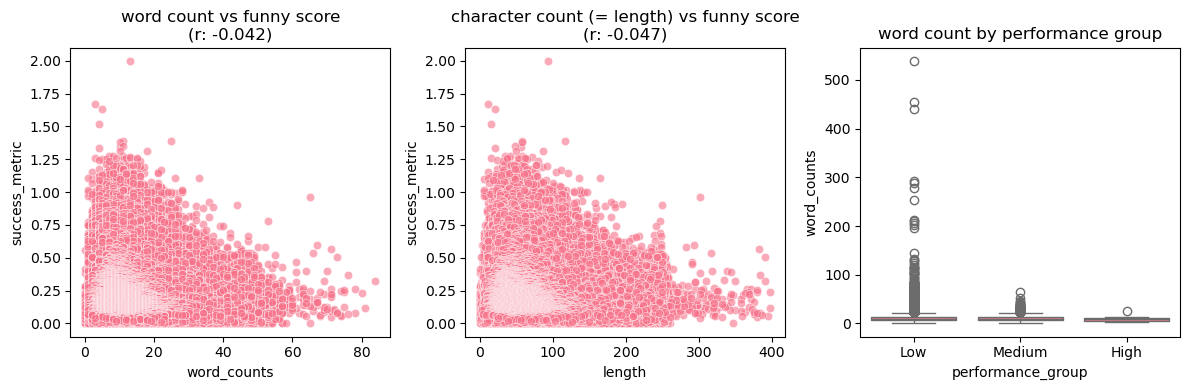

In [21]:
# style of plot
plt.style.use('default')
sns.set_palette("husl")

# scores
df['total_votes'] = df['not_funny'] + df['somewhat_funny'] + df['funny'] # this is for each caption 

# proportions for each category
df['prop_not_funny'] = df['not_funny'] / df['total_votes']
df['prop_somewhat_funny'] = df['somewhat_funny'] / df['total_votes']
df['prop_funny'] = df['funny'] / df['total_votes']

# weighted average (2 for funny, 1 for somewhat_funny, 0 for not_funny)
df['funny_score_weighted'] = (df['funny'] * 2 + df['somewhat_funny'] * 1 + df['not_funny'] * 0) / df['total_votes']
df['success_metric'] = df['funny_score_weighted']

# correlation analysis 
corr_word_score, p_word = pearsonr(df['word_counts'], df['success_metric'])
corr_char_score, p_char = pearsonr(df['length'], df['success_metric'])

print(f"\ncorrelation w/ funny Score:")
print(f"# of words correlation: {corr_word_score:.3f} (p-value: {p_word:.3f})")
print(f"# of characters correlation: {corr_char_score:.3f} (p-value: {p_char:.3f})")

df_filtered = df[(df['word_counts'] <= 100) & (df['length'] <= 400)]

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.scatterplot(data=df_filtered, x='word_counts', y='success_metric', alpha=0.6)
plt.title(f'word count vs funny score\n(r: {corr_word_score:.3f})')

plt.subplot(1, 3, 2)
sns.scatterplot(data=df_filtered, x='length', y='success_metric', alpha=0.6)
plt.title(f'character count (= length) vs funny score\n(r: {corr_char_score:.3f})')

plt.subplot(1, 3, 3)
# Create performance groups for comparison
df['performance_group'] = pd.cut(df['success_metric'], bins=3, labels=['Low', 'Medium', 'High'])

sns.boxplot(data=df, x='performance_group', y='word_counts')
plt.title('word count by performance group')

plt.tight_layout()
plt.show()



ERREUR DANS LE DATA 

In [22]:
# statistical test for performance comparison & word count performance 

top_cutoff = df['success_metric'].quantile(0.8)
bottom_cutoff = df['success_metric'].quantile(0.2)

top_captions = df[df['success_metric'] >= top_cutoff]
bottom_captions = df[df['success_metric'] <= bottom_cutoff]

print(f"\nperformance comparison:")
print(f"top 20% cutoff: {top_cutoff:.3f} ({len(top_captions)} captions)")
print(f"bottom 20% cutoff: {bottom_cutoff:.3f} ({len(bottom_captions)} captions)")

# Compare metrics
print(f"\nword count comparison:")
print(f"top performers: {top_captions['word_counts'].mean():.1f} ± {top_captions['word_counts'].std():.1f}")
print(f"bottom performers: {bottom_captions['word_counts'].mean():.1f} ± {bottom_captions['word_counts'].std():.1f}")

print(f"\nlength count comparison:")
print(f"top performers: {top_captions['length'].mean():.1f} ± {top_captions['length'].std():.1f}")
print(f"bottom performers: {bottom_captions['length'].mean():.1f} ± {bottom_captions['length'].std():.1f}")

# Statistical test
t_stat, p_val = ttest_ind(top_captions['word_counts'], bottom_captions['word_counts'])
print(f"t-test p-value words: {p_val:.4f}")

t_stat, p_val = ttest_ind(top_captions['length'], bottom_captions['length'])
print(f"t-test p-value characters: {p_val:.4f}")



performance comparison:
top 20% cutoff: 0.297 (458769 captions)
bottom 20% cutoff: 0.118 (463873 captions)

word count comparison:
top performers: 10.3 ± 4.6
bottom performers: 11.0 ± 5.8

length count comparison:
top performers: 52.1 ± 23.5
bottom performers: 56.0 ± 29.9
t-test p-value words: 0.0000
t-test p-value characters: 0.0000


*Interpretation:*

| **Metric** | **Top 20%** | **Bottom 20%** |
|-----------|-----------|--------------|
| Mean word count | 10.3 | 11.0 |
| Standard deviation (word) | 4.6 | 5.8 |
| Mean character count | 52.1 | 56.0 |
| Standard deviation (characters) | 23.5 | 29.9 |

In both counting cases (words and characters) the t-test p-value is < 0.0001, which means that the the difference in count between the two types of performers is statistically significant, in other words, the probability that this difference happened by random chance is less than 0.0001%. 

Therefore, knowing this, we can say that the top performing captions tend to be shorter in words and characters than the bottom performing ones.This conclusion is interesting, and context is necessary: it looks like the practical difference is small but because we are working with a huge amount of captions, this difference is statistically significant.  

These observations can be done also through plot visualisation, where we can see that the captions that clearly have better scores are those that are shorter.

**Do some words/vocabulary richness correlate w/ higher scores?**

Analysis of vocabulary richness using TTR (type-token ratio) where: 
- the mathematical computation is given by (#unique_words) / (total_words)
- it ranges from 0 (= no words or all words are identical) to 1 (=every word is unique)

In [23]:
# calculation of vocabulary richness metrics

# check if we already have these columns & remove them if they exist (in case of problems)
columns_to_remove = ['ttr', 'unique_words', 'total_words']
existing_cols = [col for col in columns_to_remove if col in df.columns]
if existing_cols:
    df = df.drop(columns=existing_cols)
    print(f"Removed existing columns: {existing_cols}")

# calculate vocab richness for all captions
vocab_metrics = ut.calculate_vocabulary_richness(df['caption'], remove_stopwords=True)

# new columns to the main DataFrame
df = pd.concat([df, vocab_metrics], axis=1)

# some stats
print(f"average TTR: {df['ttr'].mean():.3f}")
print(f"average unique words per caption: {df['unique_words'].mean():.1f}")
print(f"average total words per caption: {df['total_words'].mean():.1f}")
print(f"dataset size: {len(df)} captions")


average TTR: 0.989
average unique words per caption: 4.9
average total words per caption: 5.0
dataset size: 2292678 captions


<!-- The above code cell outputs the following:
```bash
    average TTR: 0.989
    average unique words per caption: 4.9
    average total words per caption: 5.0
    dataset size: 2292678 captions
``` -->

In [24]:
# comparison of top & bottom performers
top_cutoff = df['success_metric'].quantile(0.8)
bottom_cutoff = df['success_metric'].quantile(0.2)

top_captions = df[df['success_metric'] >= top_cutoff]
bottom_captions = df[df['success_metric'] <= bottom_cutoff]

print(f"\nperformance groups")
print(f"top 20% cutoff: {top_cutoff:.3f} ({len(top_captions)} captions)")
print(f"bottom 20% cutoff: {bottom_cutoff:.3f} ({len(bottom_captions)} captions)")

print(f"\nvocab richness comparison")
print("top performers:")
print(f"  TTR: {top_captions['ttr'].mean():.3f} ± {top_captions['ttr'].std():.3f}")
print(f"  Unique words: {top_captions['unique_words'].mean():.1f} ± {top_captions['unique_words'].std():.1f}")
print(f"  Total words: {top_captions['total_words'].mean():.1f} ± {top_captions['total_words'].std():.1f}")

print("\nbottom:")
print(f"  TTR: {bottom_captions['ttr'].mean():.3f} ± {bottom_captions['ttr'].std():.3f}")
print(f"  Unique words: {bottom_captions['unique_words'].mean():.1f} ± {bottom_captions['unique_words'].std():.1f}")
print(f"  Total words: {bottom_captions['total_words'].mean():.1f} ± {bottom_captions['total_words'].std():.1f}")




performance groups
top 20% cutoff: 0.297 (458769 captions)
bottom 20% cutoff: 0.118 (463873 captions)

vocab richness comparison
top performers:
  TTR: 0.990 ± 0.060
  Unique words: 4.7 ± 2.2
  Total words: 4.8 ± 2.3

bottom:
  TTR: 0.987 ± 0.068
  Unique words: 5.2 ± 2.8
  Total words: 5.3 ± 2.9



T-TESTS)
TTR (p-value) = 0.0000 ***
Unique words (p-value) = 0.0000 ***
Total words (p-value) = 0.0000 ***

correlation w/ success metric
TTR correlation: 0.013 (p-value: 0.0000)
unique words correlation: -0.058 (p-value: 0.0000)
total words correlation: -0.059 (p-value: 0.0000)


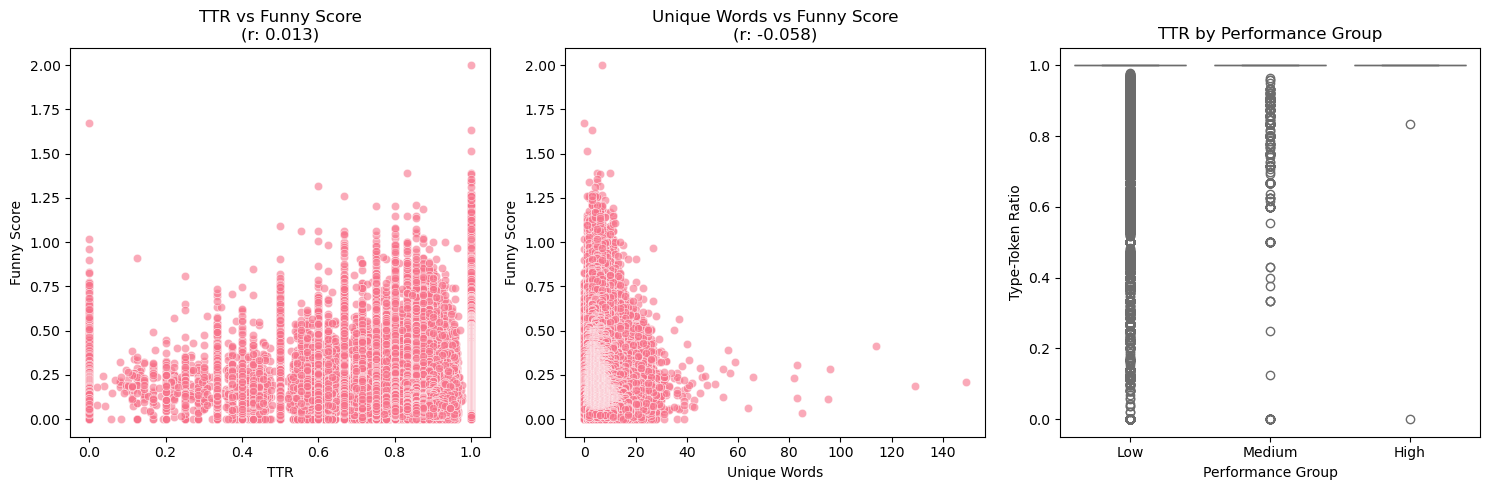

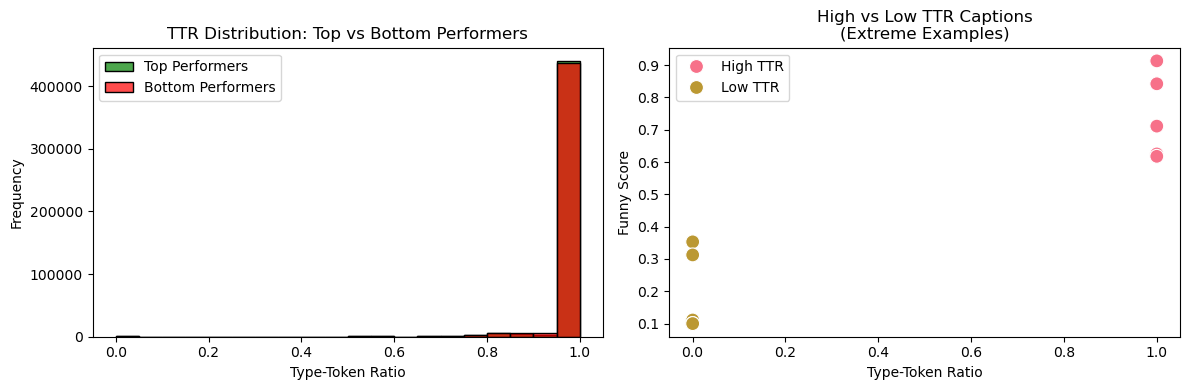

In [25]:
# stat tests 
t_stat_ttr, p_val_ttr = ttest_ind(top_captions['ttr'], bottom_captions['ttr'])
t_stat_unique, p_val_unique = ttest_ind(top_captions['unique_words'], bottom_captions['unique_words'])
t_stat_total, p_val_total = ttest_ind(top_captions['total_words'], bottom_captions['total_words'])

print(f"\nT-TESTS)")
print(f"TTR (p-value) = {p_val_ttr:.4f} {'***' if p_val_ttr < 0.001 else '**' if p_val_ttr < 0.01 else '*' if p_val_ttr < 0.05 else 'ns'}")
print(f"Unique words (p-value) = {p_val_unique:.4f} {'***' if p_val_unique < 0.001 else '**' if p_val_unique < 0.01 else '*' if p_val_unique < 0.05 else 'ns'}")
print(f"Total words (p-value) = {p_val_total:.4f} {'***' if p_val_total < 0.001 else '**' if p_val_total < 0.01 else '*' if p_val_total < 0.05 else 'ns'}")

# correlation analysis 
corr_ttr, p_corr_ttr = pearsonr(df['ttr'], df['success_metric'])
corr_unique, p_corr_unique = pearsonr(df['unique_words'], df['success_metric'])
corr_total, p_corr_total = pearsonr(df['total_words'], df['success_metric'])

print(f"\ncorrelation w/ success metric")
print(f"TTR correlation: {corr_ttr:.3f} (p-value: {p_corr_ttr:.4f})")
print(f"unique words correlation: {corr_unique:.3f} (p-value: {p_corr_unique:.4f})")
print(f"total words correlation: {corr_total:.3f} (p-value: {p_corr_total:.4f})")

ut.plot_linguistic_metrics(df, top_captions, bottom_captions, corr_ttr, corr_unique)


*Interpretation of the results:* 

we can observe that the TTR difference is minimal (there is only a 0.975 difference, which is a 0.9% relative difference). Knowing that p = 0.02, this difference is statistically significant (it's not from random noise) but it is oractically meaningless (the effect is not large enough to matter here). We can also see that both groups have a high TTR, meaning nearly all words are unique, so there is not vocabulary influence on humour. 

## 5. Semantic Analysis

Unfortunately, after doing our research, we have come to the conclusion that it was not feasible to try to separate our captions in a relevant way with regard to the previously mentioned categories. 

| Categories of Humour |
|-----------|
|Dark Humour|
|Irony|
|Social Commentary|
|Wordplay|
|Absurdity|


The article is publicly available at [this link](https://www.sciencedirect.com/science/article/pii/S2772662224000547). 

More specifically, we have looked the following research article : 
*An automatic humor identification model with novel features from Berger’s typology and ensemble models*, written by Majahan and Zaveri. 

This article further reinforced the idea that we neither had the means, nor enough time to utilize those findings. Although very interesting, we have decided to utltimately disregard this research question.

## 6. Context Analysis



As explained in our README, we have eventually decided to drop our Contextual Analysis after exploring a reduced snipet of the GDELT database. Here, you can have insight into what it looks like :  

---
```python
    #dataset_path = file_path = pd.read_txt(r"C:\Users\hanna\ADA\2025\newyorker_caption_contest\data\510.csv")
    dataset_path = r"C:\Users\hanna\ADA\2025\additional_dataset\GDELT.MASTERREDUCEDV2.txt"
    from itertools import islice

    with open(dataset_path, "r") as f:
        for line in f.readlines()[:5]:
            print(line.strip())
```
---
The code above outputs the following:

```bash
    Date	Source	Target	CAMEOCode	NumEvents	NumArts	QuadClass	Goldstein	SourceGeoType	SourceGeoLat	SourceGeoLong	TargetGeoType	TargetGeoLat	TargetGeoLong	ActionGeoType	ActionGeoLat	ActionGeoLong
    19790101	AFR	FRA	043	1	4	1	2.8
    19790101	AFR	FRA	050	2	9	1	3.5
    19790101	AFR	FRAGOV	043	2	19	1	2.8	1	46	2	1	46	2	1	46	2
    19790101	AFR	ZMB	100	2	18	3	-5
```

As you can see, the data goes back to January 1rst 1979 and is quite a swiss cheese. More specifically, we are missing quite a lot of data in each line. Each one of them represent a new entry updated each 15mins automatically by GDELT.

Finally, this specific file took a really long time to download as it is 6GB (even if it is a reduced version) and really hard to be found on the GDELT website.

We also tried downloading the time window of interest for our dataset which is from 2016 to 2024. You can download it yourself by using the python script [GDELT_dataloader.py](utils/GDELT_dataloader.py) for a specified datetime range. We realised while downloading that for a 30 days period, we already had 3GB or so of raw data. For the whole dataset from 2016 to 2024 this would give us an **enormous augmented dataset of 288GB!**

This dataset is simply way to large to deal with on our personal computer and also the data wrangling involved to clean it is in itself a whole project. This outcome further encouraged us to drop the idea of performing contextual analysis, since the rest of our findings encourages us to follow other analysis ideas. 

## 7. Conclusion

To conclude, up until now, we were not only able to dive into the provided NewYorker’s dataset, but we also managed to perform : 

Filtering and transformation of the data through data wrangling. This confirmed that we are on a good track in handling the data in its size, and also that we were able to verify that we understood the data’s format (CSV, JSON, png…). Through different methods to fill in missing data, as well as plots and graphs, we were able to visualize the main features of the dataset. We still need to finish our functions that correct the entire dataset.
We also considered ways to enrich the data, through an additional dataset, but also using calculations and generative AI for image descriptions.
Furthermore, we are confident that our proposed plan is not only feasible, but highly likely to give us an engaging and gripping datastory. When it comes to the methods we have found, these will be further dived into in the following weeks, as exposed in our proposed timeline. We have proposed statstical means which will be used to answer to dig deeper into our research questions.

Ultimately, we are looking forward to not only dive deeper, but also construct a robust story around the question : What makes a joke funny ?